# Does the pairs method hold up on Kalpa Retail's baskets?

**Week 4, Wednesday, the TA-led lab, after chapter 10.** **Applies:** Basket analysis on
the order items (chapter 5, notebook 05); The confidence trap; lift near one (chapter 4,
notebook 04); The support floor and the watch list (chapter 6, notebook 06); Cross-sell and
upsell reasoning; expected value in rupees (chapter 9, notebook 09).

Kalpa Retail's merchandising team, which decides
which products are bundled and promoted, wants to pair every product with the Rs 199 phone
charger, "because it is in 80 percent of baskets", to give Retail-Plus members (Kalpa's
paid membership tier) a reason to come back. The head of merchandising asks which pairs
to promote and what each promotion is worth in rupees before any money is spent. The data
are Kalpa's own: the warehouse's 1,000 orders from April to September 2026, now with their
order lines (`order_items`: order, product, quantity, unit price) and the product list.

**Who needs the answer.** The head of merchandising, whose bundle budget goes wherever the
lab's numbers point.

**The questions on the way.** What does a basket mean in Kalpa's data? What do twelve
baskets say when counted by hand? How often is the charger in a basket, and what is its
lift with each product? Which pair beats chance above a 5 percent floor, and which strong
pair is too thin to promote?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

orders = pd.read_csv("../data/C2_W04_D03_kalpa_orders_STUDENT.csv")
lines = pd.read_csv("../data/C2_W04_D03_kalpa_order_items_STUDENT.csv")
products = pd.read_csv("../data/C2_W04_D03_kalpa_products_STUDENT.csv")
lines = lines.merge(products[["product_id", "name"]], on="product_id")
line_total = (lines.quantity * lines.unit_price).groupby(lines.order_id).sum()
check("every order's lines add up to its amount",
      (line_total.reindex(orders.order_id).values == orders.amount.values).all())
consumer = orders[orders.segment != "Business"]
print(f"{len(orders):,} orders: {len(consumer)} consumer baskets, "
      f"{(orders.segment == 'Business').sum()} Business orders of one product in bulk")

PASS every order's lines add up to its amount
1,000 orders: 812 consumer baskets, 188 Business orders of one product in bulk


## What does a basket mean here, and what do twelve baskets say?

A basket is one consumer order with its lines; a Business order holds one product bought
in bulk, so it is left out. The TA hands out twelve baskets on paper. Count by hand first:
the charger's share, the screen protector's confidence toward the charger and its lift
with the charger, and the lift of wireless earphones with their case. The cell below prints
those numbers to check your count.

KR-00001 USB-C cable, notebook A5, phone charger 20W
KR-00002 cable organiser, earphone jack adapter, notebook A5, pen set, phone charger 20W, phone grip
KR-00004 LED desk lamp, extension cord, phone charger 20W
KR-00005 phone charger 20W, power bank 10000mAh, screen protector
KR-00006 earphone jack adapter, extension cord, pen set, phone charger 20W, phone grip
KR-00008 LED desk lamp, notebook A5, pen set, phone charger 20W
KR-00009 LED desk lamp, notebook A5, pen set, phone grip
KR-00011 USB-C cable, cable organiser, earphone jack adapter, extension cord, screen protector
KR-00157 LED desk lamp, extension cord, pen set, phone charger 20W, phone grip, wireless earphones
KR-00190 earphone case, extension cord, notebook A5, phone charger 20W, power bank 10000mAh, wireless earphones
KR-00340 USB-C cable, cable organiser, earphone case, earphone jack adapter, notebook A5, power bank 10000mAh
KR-00938 cable organiser, earphone case, phone charger 20W, phone grip, screen protector, wireless

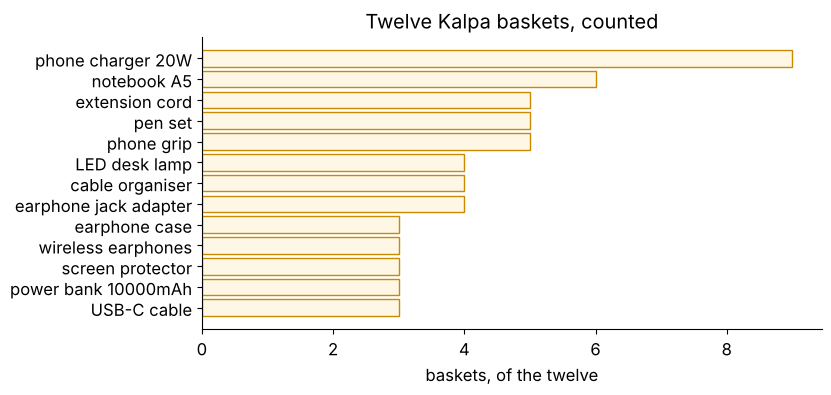

PASS twelve baskets


In [2]:
twelve_ids = "KR-00001, KR-00002, KR-00004, KR-00005, KR-00006, KR-00008, KR-00009, KR-00011, KR-00157, KR-00190, KR-00340, KR-00938".split(", ")
twelve = lines[lines.order_id.isin(twelve_ids)].groupby("order_id").name.apply(set)
for oid, held in twelve.items():
    print(oid, ", ".join(sorted(held)))
charger = twelve.apply(lambda x: "phone charger 20W" in x)
protector = twelve.apply(lambda x: "screen protector" in x)
phones = twelve.apply(lambda x: "wireless earphones" in x)
case = twelve.apply(lambda x: "earphone case" in x)
conf_sp = (protector & charger).sum() / protector.sum()
lift_sp = (protector & charger).sum() * 12 / (protector.sum() * charger.sum())
lift_ec = (phones & case).sum() * 12 / (phones.sum() * case.sum())
print(f"charger in {charger.mean():.2f} of the twelve; screen protector to charger: "
      f"confidence {conf_sp:.2f}, lift {lift_sp:.2f}; earphones with case: lift {lift_ec:.2f}")
count = Counter(x for held in twelve for x in held)
fig, ax = plt.subplots(figsize=(8, 3.8))
names = sorted(count, key=count.get)
ax.barh(names, [count[x] for x in names], color="#FFF7E6", edgecolor="#C98A00")
ax.set_xlabel("baskets, of the twelve"); ax.set_title("Twelve Kalpa baskets, counted")
plt.show()
check("twelve baskets", len(twelve) == 12)

### Your turn: how often is the charger in a basket, and what is its lift with each product?

Build `baskets = lines[lines.order_id.isin(consumer.order_id)].groupby("order_id").name.apply(set)`.
Print the charger's share of baskets. Then, for every product in at least 2 percent of
baskets, print its confidence toward the charger and its lift with the charger. Write one
sentence for merchandising on what the numbers say about "it is in 80 percent of baskets".
Checks you can run yourself: your baskets number 812, every share sits between 0 and 1,
and a pair's lift reads the same from both sides.

### Your turn: which pair beats chance above a 5 percent floor, and which is too thin?

Count every pair with `Counter` over `combinations(sorted(basket), 2)`, as notebook 05 did
on the canteen and notebook 08 on Instamart's carts. With 812 baskets, a floor of 1 percent would be
about 8 baskets, too thin to trust, so the lab sets its floor at
5 percent, about 41 baskets. Keep the pairs at or above it and rank them
by lift; then look below the floor for a pair with a high lift on two or three baskets.
For the strongest pair above the floor, find which segment its baskets come from:
`orders.set_index("order_id").loc[ids, "segment"].value_counts()` counts the segments of a
list of basket ids. Kalpa's consumer segments are Retail-Core, Retail-Plus and Student, and
a pair whose baskets come mostly from one segment is a pair to promote to that segment.

## Can the data carry the answer?

Before a number goes to merchandising, two checks that need no pair counts: how many lines
a basket holds, and whether every amount reconciles to its lines. A basket of one line
holds no pair, so the first picture says how many baskets the pairs table can use. An
order lists at most eight products, and a bigger order buys more units of each, so the
larger orders all sit at eight lines.

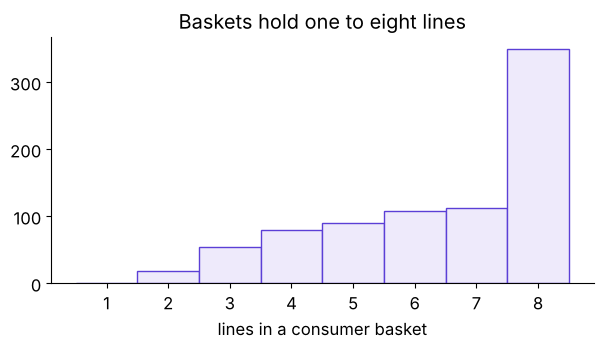

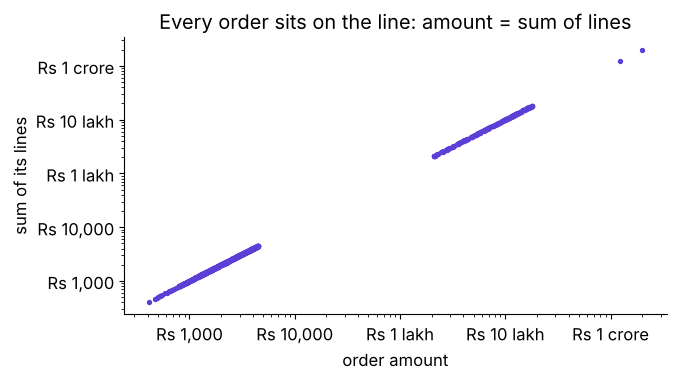

PASS consumer baskets hold one to eight lines
PASS Business orders hold one line each
PASS the charger lists at Rs 199


In [3]:
per_basket = lines[lines.order_id.isin(consumer.order_id)].groupby("order_id").size()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_basket, bins=range(1, 10), color="#EEEAFB", edgecolor="#5B3FD6", align="left")
ax.set_xlabel("lines in a consumer basket"); ax.set_title("Baskets hold one to eight lines")
plt.show()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(orders.amount, line_total.reindex(orders.order_id), s=8, color="#5B3FD6")
ax.set_xscale("log"); ax.set_yscale("log")
rupees = [1e3, 1e4, 1e5, 1e6, 1e7]
names = ["Rs 1,000", "Rs 10,000", "Rs 1 lakh", "Rs 10 lakh", "Rs 1 crore"]
ax.set_xticks(rupees, names); ax.set_yticks(rupees, names)
ax.set_xlabel("order amount"); ax.set_ylabel("sum of its lines")
ax.set_title("Every order sits on the line: amount = sum of lines")
plt.show()
check("consumer baskets hold one to eight lines", per_basket.between(1, 8).all())
check("Business orders hold one line each",
      (lines[lines.order_id.isin(orders[orders.segment == "Business"].order_id)]
       .groupby("order_id").size() == 1).all())
check("the charger lists at Rs 199", products.set_index("name").loc["phone charger 20W", "list_price"] == 199)

## What will merchandising's proposal cost, and what do you bring back?

The unguided Kalpa exercise prices the charger proposal as chapter 9 priced the kirana's
card. The charger lists at
Rs 199 and costs Kalpa Rs 120, so the proposed
Rs 20 off leaves Rs 59 of margin on every
bundled charger, and every basket that already holds the charger hands that discount back
for an add that would have happened anyway. Bring back three lines: the charger's share and
its lift with the products it would be bundled with, the pair you would promote with its
support and lift, and the pair you would watch, with the number of baskets it rests on.